In [60]:
import starfile
from pathlib import Path
import seaborn as sns
import numpy as np
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

In [58]:
tomograms = ["20240819_HippWaffle_32","20240819_HippWaffle_45","20240819_HippWaffle_52","20240819_HippWaffle_135","20240820_HippWaffle_16"]
aunp_dfs = {}
for tomogram in tomograms:

    basefolder = Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingJE/15F1and5F11_tomograms")
    aunp_star = basefolder / tomogram / "fiducial_tracking" / "aunps" / "aunp_tm.star"
    presynaptic_txts = list((basefolder / tomogram / "fiducial_tracking" / "aunps").glob("presynatpticmembranes*.txt"))
    postsynaptic_txts = list((basefolder / tomogram / "fiducial_tracking" / "aunps").glob("postsynapticmembranes*.txt"))

    aunp_data = starfile.read(aunp_star)
    presynaptic_data = [np.loadtxt(f) for f in presynaptic_txts]
    presynaptic_data = np.concatenate(presynaptic_data)
    presynaptic_data.shape
    postsynaptic_data = [np.loadtxt(f) for f in postsynaptic_txts]
    postsynaptic_data = np.concatenate(postsynaptic_data)
    pre_kd = cKDTree(presynaptic_data)
    post_kd = cKDTree(postsynaptic_data)

    aunp_pos = aunp_data[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values
    aunp_data["Size"] = aunp_data["faTomo_gaussianFitSigmaX"] * aunp_data["faTomo_gaussianFitSigmaY"] * aunp_data["faTomo_gaussianFitSigmaZ"]
    pre_dists, pre_idxs = pre_kd.query(aunp_pos)
    post_dists, post_idxs = post_kd.query(aunp_pos)
    aunp_data["pre_dist"] = pre_dists
    aunp_data["post_dist"] = post_dists

    aunp_dfs[tomogram] = aunp_data


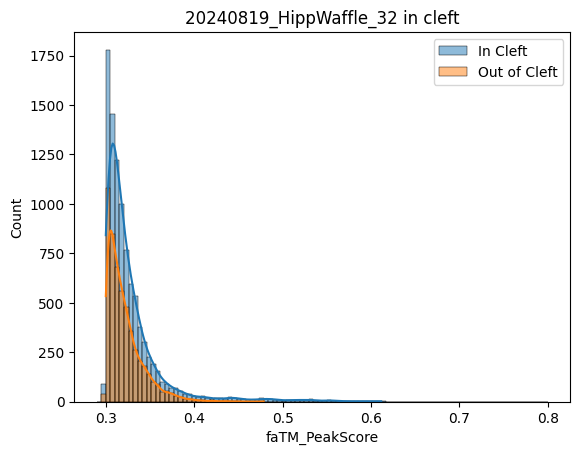

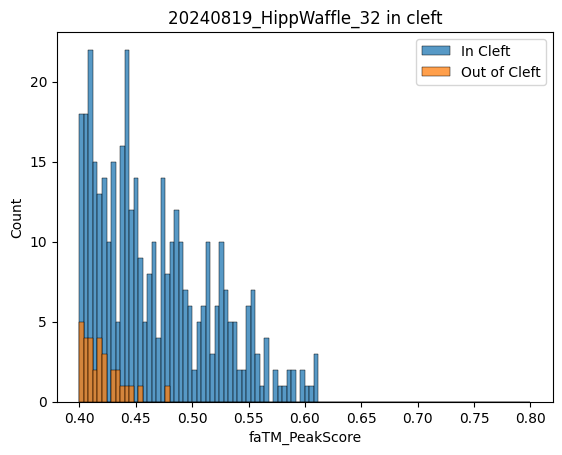

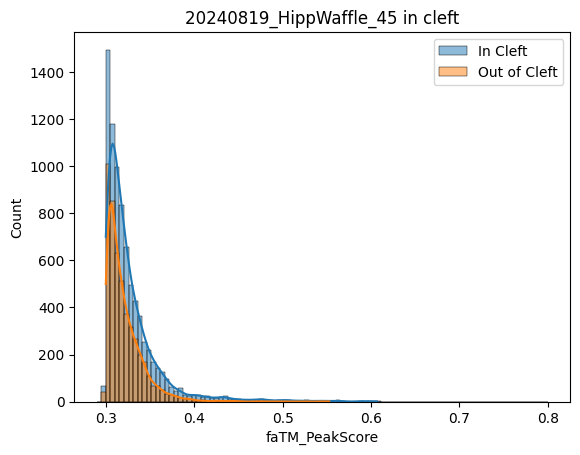

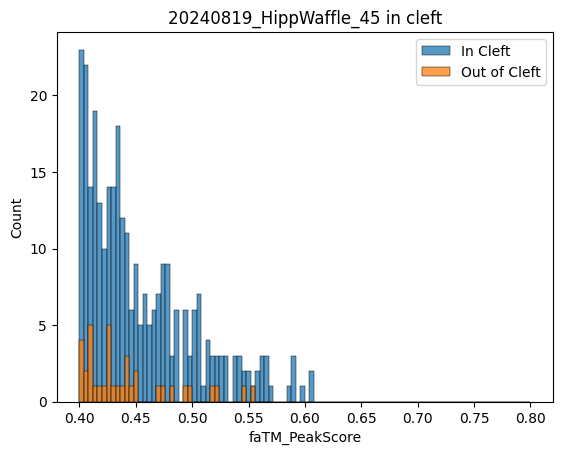

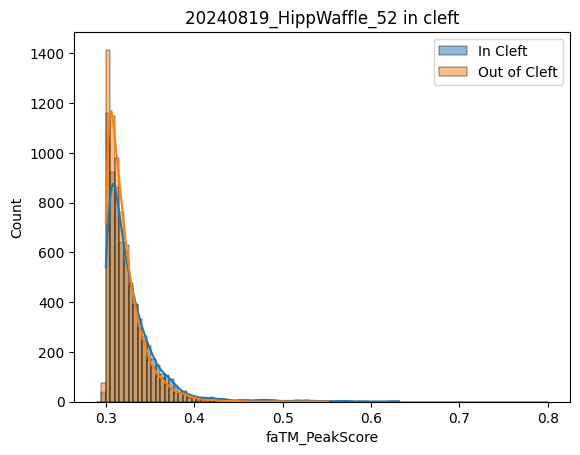

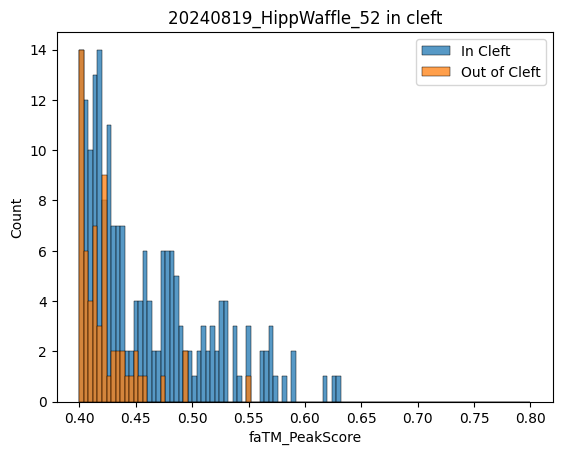

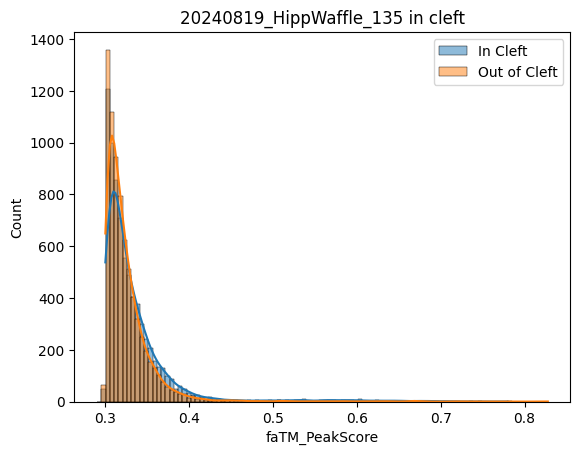

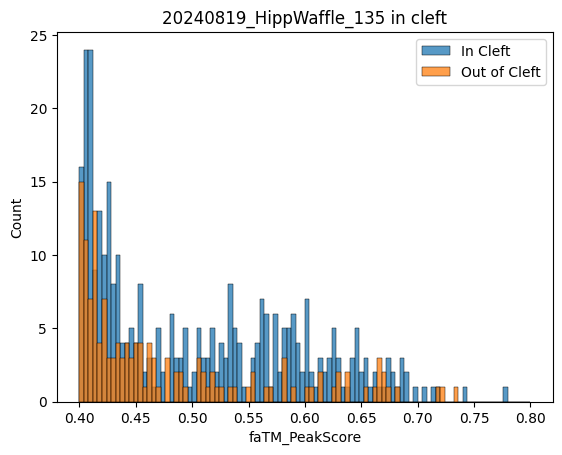

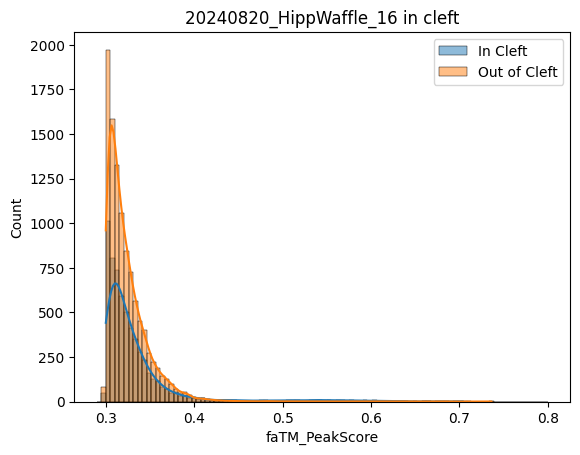

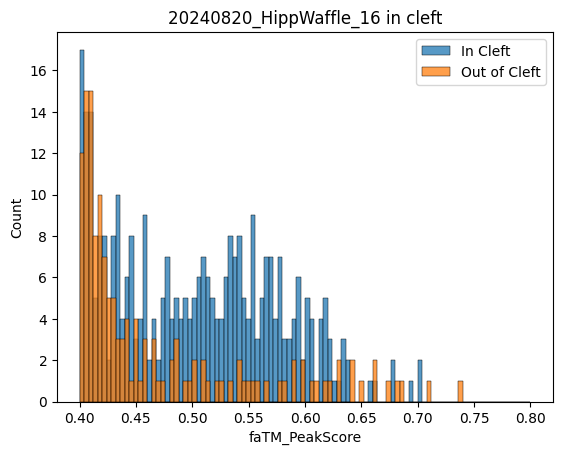

In [82]:
for tomogram in tomograms:
    aunp_data = aunp_dfs[tomogram]
    in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
    out_of_cleft_aunps = aunp_data[(aunp_data["pre_dist"] >= 250) | (aunp_data["post_dist"] >= 250)]
    sns.histplot(in_cleft_aunps["faTM_PeakScore"], bins=100, binrange=(0.29,0.8), kde=True, label="In Cleft")
    plt.title(tomogram+" in cleft")
    sns.histplot(out_of_cleft_aunps["faTM_PeakScore"], bins=100, binrange=(0.29,0.8), kde=True, label="Out of Cleft")
    # Make inset zoomign in on the high scoring peaks
    plt.legend()
    plt.show()
    sns.histplot(in_cleft_aunps["faTM_PeakScore"], bins=100, binrange=(0.4,0.8), label="In Cleft")
    plt.title(tomogram+" in cleft")
    sns.histplot(out_of_cleft_aunps["faTM_PeakScore"], bins=100, binrange=(0.4,0.8), label="Out of Cleft")
    # Fit a gaussian to out of cleft data
    #from scipy.stats import norm
    #mean, std = norm.fit(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"])
    # PLot a line at 2x std below mean
    #plt.axvline(mean-3*std, color="red")
    plt.legend()
    plt.show()

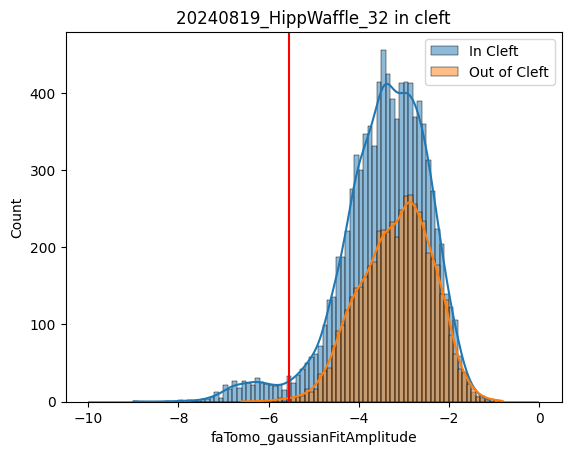

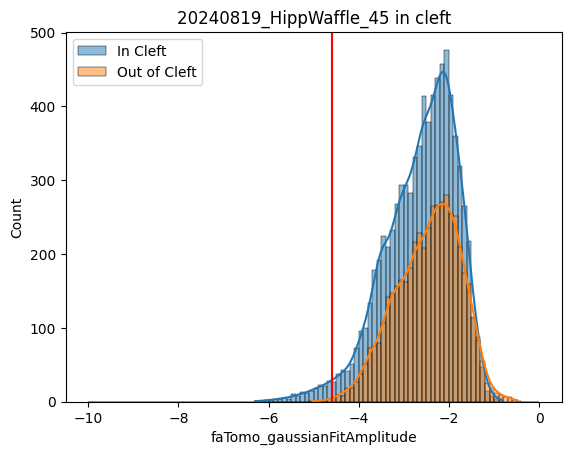

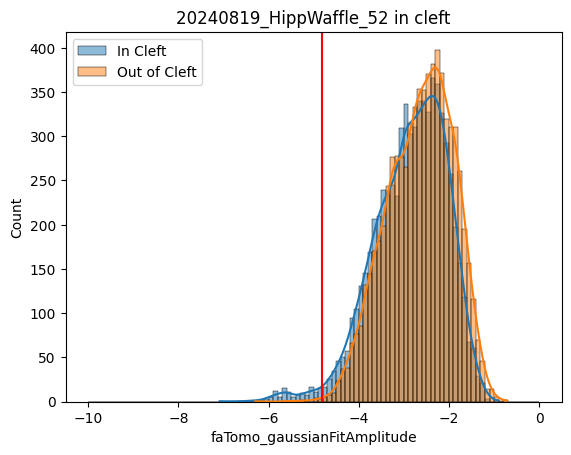

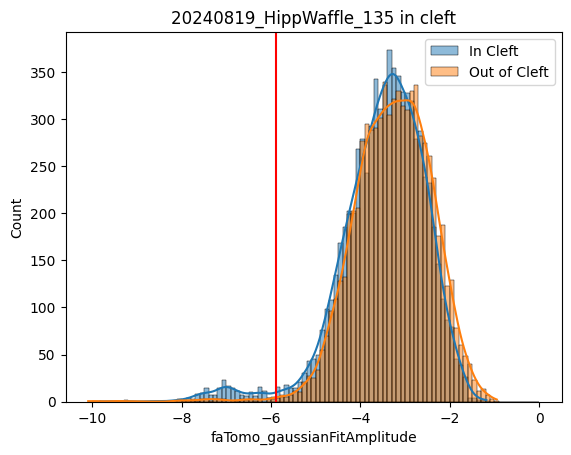

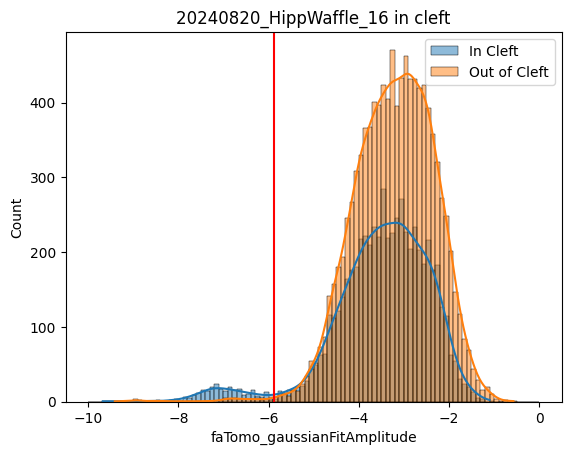

In [84]:
for tomogram in tomograms:
    aunp_data = aunp_dfs[tomogram]
    in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
    out_of_cleft_aunps = aunp_data[(aunp_data["pre_dist"] >= 250) | (aunp_data["post_dist"] >= 250)]
    sns.histplot(in_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100, binrange=(-10.0,0.0), kde=True, label="In Cleft")
    plt.title(tomogram+" in cleft")
    sns.histplot(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100, binrange=(-10.0,0.0), kde=True, label="Out of Cleft")
    # Make inset zoomign in on the high scoring peaks
    
    # Fit a gaussian to out of cleft data
    from scipy.stats import norm
    mean, std = norm.fit(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"])
    # PLot a line at 2x std below mean
    plt.axvline(mean-3*std, color="red")
    plt.legend()
    plt.show()

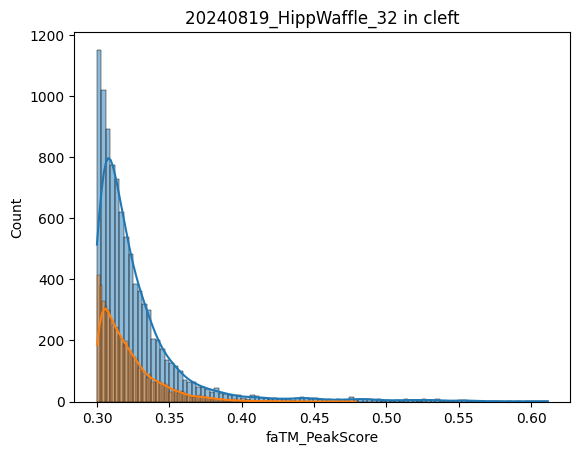

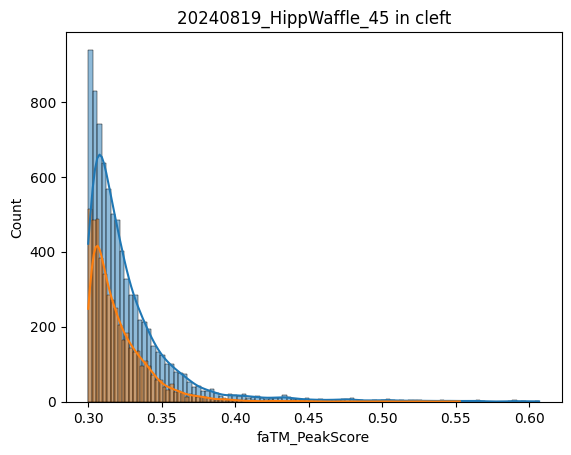

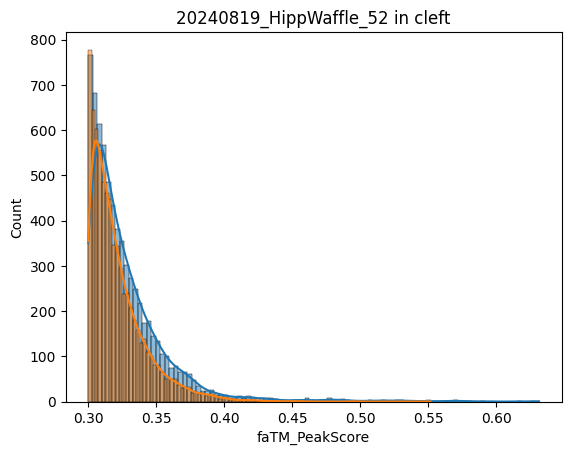

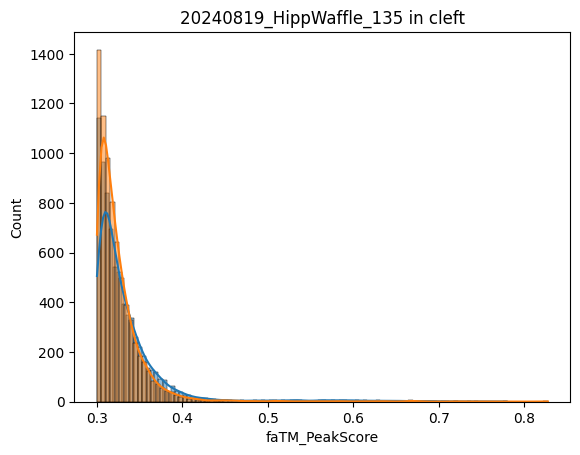

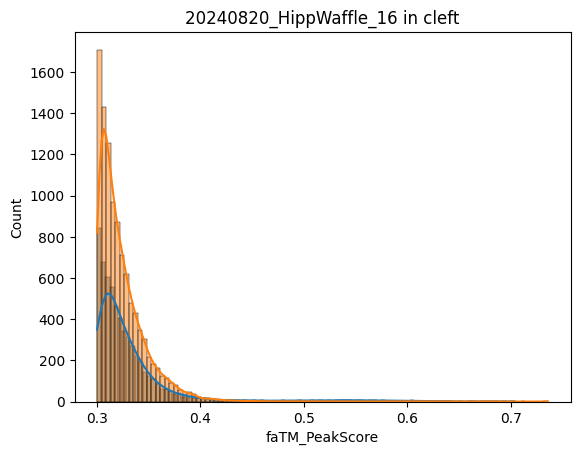

In [71]:
for tomogram in tomograms:
    aunp_data = aunp_dfs[tomogram]
    in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
    out_of_cleft_aunps = aunp_data[(aunp_data["pre_dist"] >= 250) | (aunp_data["post_dist"] >= 250)]
    sns.histplot(in_cleft_aunps["faTM_PeakScore"], bins=100, kde=True, label="In Cleft")
    plt.title(tomogram+" in cleft")
    sns.histplot(out_of_cleft_aunps["faTM_PeakScore"], bins=100, kde=True, label="Out of Cleft")
    plt.show()

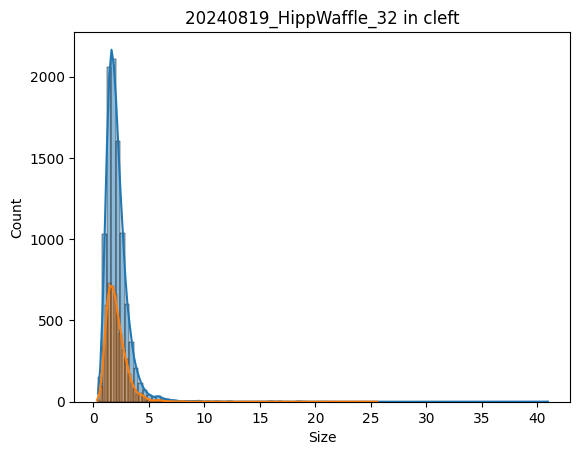

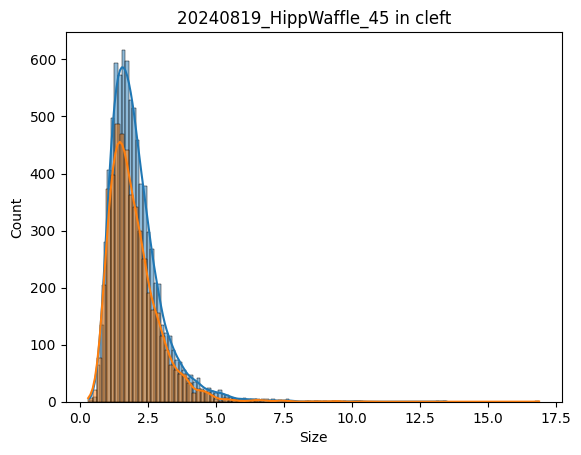

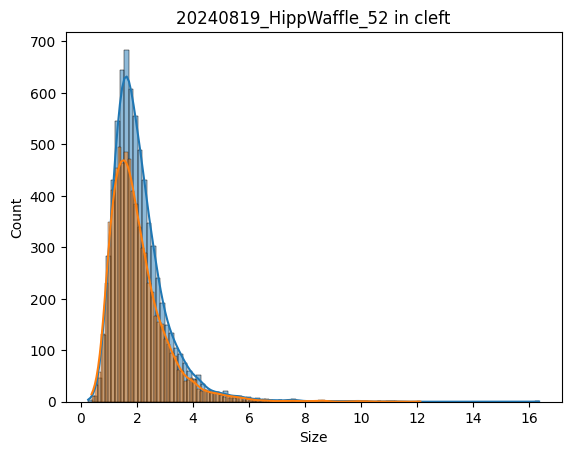

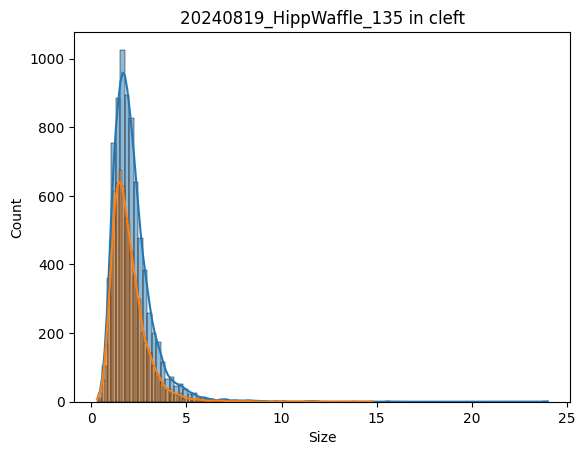

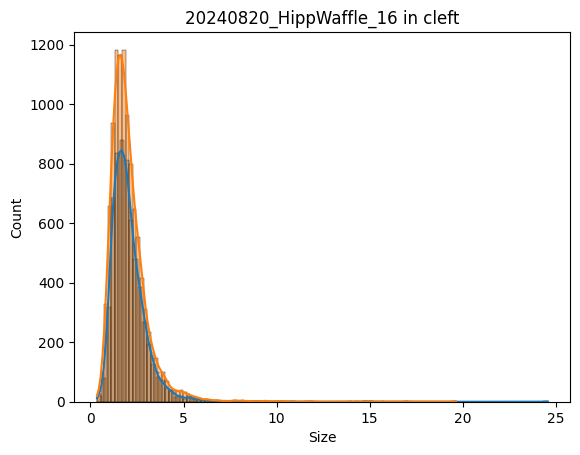

In [72]:
for tomogram in tomograms:
    aunp_data = aunp_dfs[tomogram]
    in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
    out_of_cleft_aunps = aunp_data[(aunp_data["pre_dist"] >= 250) | (aunp_data["post_dist"] >= 250)]
    sns.histplot(in_cleft_aunps["Size"], bins=100, kde=True, label="In Cleft")
    plt.title(tomogram+" in cleft")
    sns.histplot(out_of_cleft_aunps["Size"], bins=100, kde=True, label="Out of Cleft")
    plt.show()

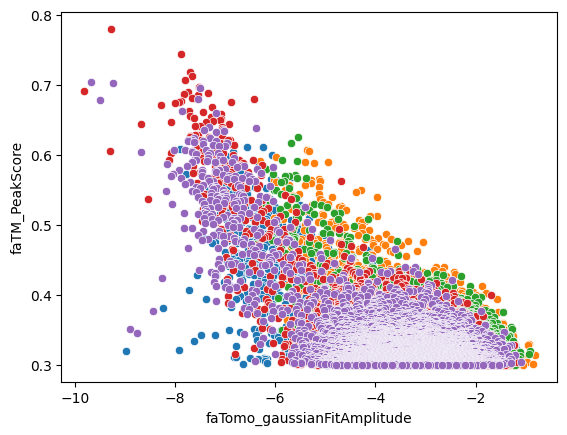

In [65]:
for tomogram in tomograms:
    aunp_data = aunp_dfs[tomogram]
    in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
    sns.scatterplot(data=in_cleft_aunps, x="faTomo_gaussianFitAmplitude", y="faTM_PeakScore")
    

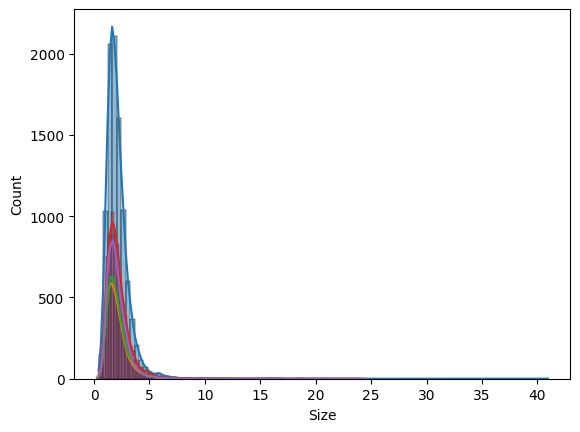

In [66]:
for tomogram in tomograms:
    aunp_data = aunp_dfs[tomogram]
    in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
    sns.histplot(in_cleft_aunps["Size"], bins=100, kde=True)

In [20]:
presynaptic_data = [np.loadtxt(f) for f in presynaptic_txts]
presynaptic_data = np.concatenate(presynaptic_data)
presynaptic_data.shape
postsynaptic_data = [np.loadtxt(f) for f in postsynaptic_txts]
print(postsynaptic_data[0].shape)
postsynaptic_data = np.concatenate(postsynaptic_data)
print(postsynaptic_data.shape)

(673393, 3)
(1216239, 3)


In [41]:
pre_kd = cKDTree(presynaptic_data)
post_kd = cKDTree(postsynaptic_data)

aunp_pos = aunp_data[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values
aunp_data["Size"] = aunp_data["faTomo_gaussianFitSigmaX"] * aunp_data["faTomo_gaussianFitSigmaY"] * aunp_data["faTomo_gaussianFitSigmaZ"]

In [42]:
pre_dists, pre_idxs = pre_kd.query(aunp_pos)
post_dists, post_idxs = post_kd.query(aunp_pos)
aunp_data["pre_dist"] = pre_dists
aunp_data["post_dist"] = post_dists

In [53]:
in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
in_cleft_aunps_dense = in_cleft_aunps[in_cleft_aunps["faTomo_gaussianFitAmplitude"] < -5.4]

<Axes: xlabel='faTM_PeakScore', ylabel='Count'>

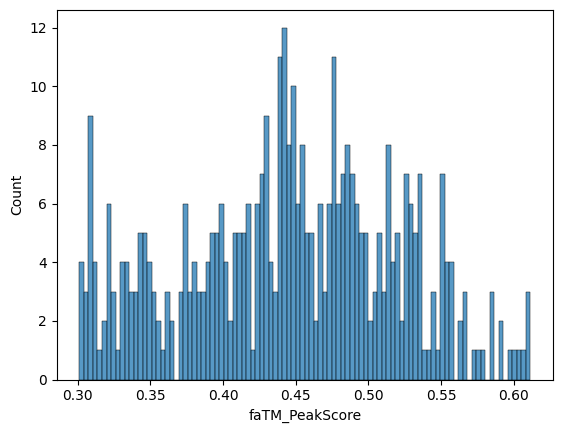

In [54]:
sns.histplot(in_cleft_aunps_dense["faTM_PeakScore"], bins=100)

<Axes: xlabel='faTomo_gaussianFitAmplitude', ylabel='Count'>

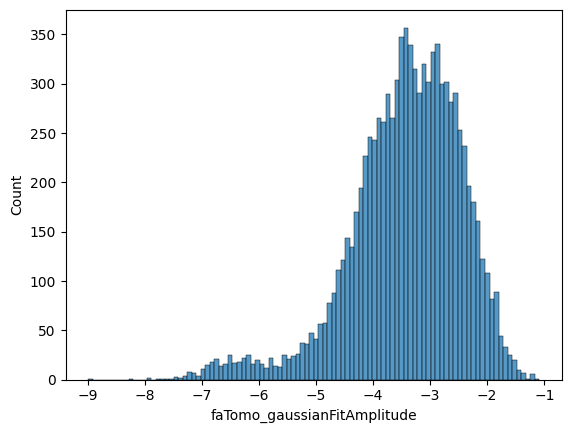

In [55]:
sns.histplot(in_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100)

<Axes: xlabel='faTomo_gaussianFitAmplitude', ylabel='Count'>

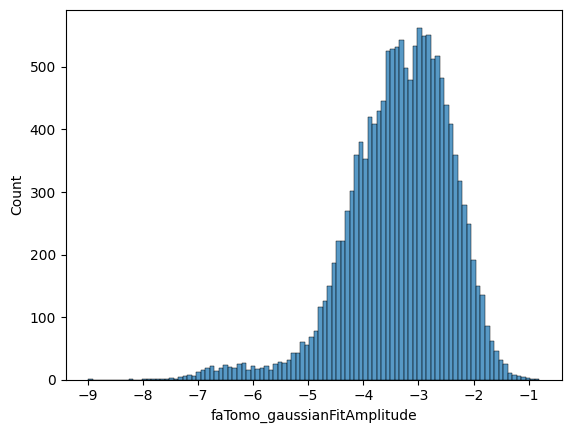

In [56]:
sns.histplot(aunp_data["faTomo_gaussianFitAmplitude"], bins=100)

<Axes: xlabel='Size', ylabel='Count'>

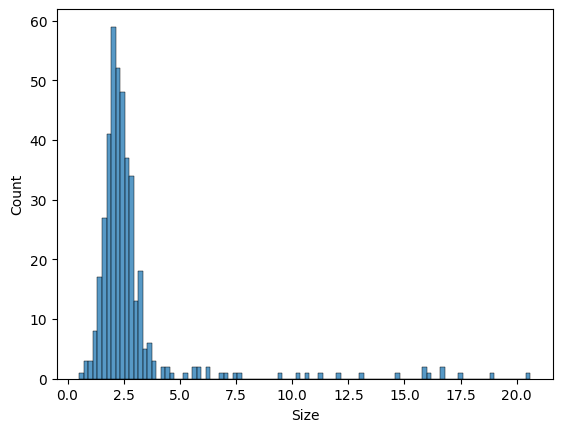

In [57]:
sns.histplot(in_cleft_aunps_dense["Size"], bins=100)